In [1]:
#--------------LOAD EVERYTHING----------------

!pip install nilearn scikit-learn nibabel matplotlib -q #installs the tools, ! runs it as terminal command instead of, -q keeps it quiet

#loads the tools
import numpy as np #numpy does math on big list of numbers, np is just nickname
import nibabel as nib #nibabel opens brain scan files
import matplotlib.pyplot as plt #draws plots
from nilearn import datasets #provides the brain data

mni = datasets.fetch_icbm152_2009() # downloads the MNI152 average brain and its tissue maps

#nib.load opens a file, and .get_fdata() turns it into 3D array of numbers
t1  = nib.load(mni['t1']).get_fdata() #t1 is the brain scan (brightness)
gm  = nib.load(mni['gm']).get_fdata()
wm  = nib.load(mni['wm']).get_fdata()
csf = nib.load(mni['csf']).get_fdata()
# gm, wm,csf are probability maps (how likely each voxel is that tissue)
mask = nib.load(mni['mask']).get_fdata() > 0 #is True where theres brain, the >0 turns numbers into True/False

print("T1 shape:", t1.shape)
print("GM shape:", gm.shape)
print("Brain voxels:", mask.sum())
#3 print lines check that the shapes match and count brain voxels

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


[fetch_icbm152_2009] Dataset directory found: /root/nilearn_data/icbm152_2009

T1 shape: (197, 233, 189)
GM shape: (197, 233, 189)
Brain voxels: 1886539


In [2]:
#------------BASELINE SEGMENTATION--------------
#1) import k-means
from sklearn.cluster import KMeans #brings in k-means(the sorting into piles tool)

#2) pull out brain voxel as one list
v = t1[mask] #brain is 3D grid, but most of it is empty space... mask marks which voxels are brain... t1[mask] pulls out just brain voxels as 1 long list of 1.9 million numbers (pulls out brain voxels as a list)
#[mask] keeps only brain voxels

#3) rescale brightness to 0-1
v = (v - v.min()) / (v.max() - v.min()) #rescales so the darkest is 0 and brightest is 1

#4) build answer key: for each voxel it takes the 3 tissue probabilities and picks the biggest 1, giving correct label: 0 = fluid, 1 = grey, 2 = white
probs = np.stack([csf, gm, wm], axis=-1) #np.stack combines 3 probability maps, so each voxel has 3 numbers
truth = np.argmax(probs, axis=-1)[mask] #np.argmax picks which of 3 is biggest: 0 for CSF, 1 for grey, 2 for white... truth is the correct label for every voxel

#5) segment function (labeling recipe) --> picks 100k random voxels, learns 3 from them w/ k-means (fit), ranks the piles dark to bright (0-2), labels all 1.9 million voxels
def segment(values, seed=42):
    # learn the 3 piles from a 100k random sample (faster)
    idx = np.random.RandomState(seed).choice(len(values), 100000, replace=False) # picks 100,000 random voxel positions, replace=False means no repeats, K-means only learns from these since using all 1.9 million is slow
    km = KMeans(n_clusters=3, n_init=3, random_state=seed) #makes k-means that sorts into 3 piles, n_init means try 3 starting guesses and keep the best, random_state makes results repeatable
    km.fit(values[idx].reshape(-1, 1)) #fit learns the piles from the sample, reshape(-1,1) turns the flat list into a single column, which is the shape k-means needs

    # pile numbers are random, so rank them dark -> bright
    order = np.argsort(km.cluster_centers_.flatten()) #cluster_centers_ holds each piles avg brightness
    rank = np.argsort(order)
    # these 2 argsort lines convert pile numbers into ranks...
    #so 0 is always the darkest pile (fluid), 1 the middle (grey), and 2 the brightest (white)
    return rank[km.predict(values.reshape(-1, 1))] #km.predict sorts all 1.9 million voxels into the piles and the function returns the ranks

#6) dice function (grading recipe) --> measures overlap btwn labels and answer key for 1 tissue from 0 to 1
# A is "voxels I call grey", B is "voxels answer key calls grey", A&B is voxels in both
# formula = 2*overlap / (size A + size B) --> perfect overlap gives 1, none gives 0
def dice(pred, truth, label):
    A, B = (pred == label), (truth == label)
    return 2 * (A & B).sum() / (A.sum() + B.sum())

#7) runs segment on the clean brain  --> first time labeling runs
pred = segment(v) #runs whole labeling on the clean brain (pred is label for every voxel)

#8) grades it - prints dice for each tissue - each one measures how well k-means labels (pred) overlap w/ answer key labels (truth) for 1 tissue
for name, i in [("CSF", 0), ("Grey matter", 1), ("White matter", 2)]:
    print(name, "Dice:", round(dice(pred, truth, i), 3))

#9) counts grey matter volume (counts voxels labeled grey, and each is 1 mm3, so count is the volume: 901,828mm3 --> baseline number)
print("Grey matter volume (mm3):", (pred == 1).sum()) #counts grey voxels (pred == 1), which is grey matter volume

CSF Dice: 0.657
Grey matter Dice: 0.889
White matter Dice: 0.932
Grey matter volume (mm3): 901828


In [3]:
#---------ADDS FAKE SCANNER GRADIENT-------------

#1) gets every brain voxel's position
xyz = np.argwhere(mask).astype(float) #xyz is each brain voxel's position

#2) pulls out just the height
z = xyz[:, 2] #z = height

#3) rescales height 0-1
z01 = (z - z.min()) / (z.max() - z.min()) #z01 rescales height to 0 (bottom) to 1 (top)

#4) builds fake lighting
bias = 1.0 + 0.3 * z01 #bias is the lighting: 1 at bottom, 1.3 at top, smooth in btwn

#5) corrupts the brightness
v_bad = v * bias #multiplies each voxels brightness by its lighting, top voxels get 30% brighter (corrupts scan)

#6) re-run the same k-means on the corrupted brightness
pred_bad = segment(v_bad) #gets fooled since k-means only knows brightness --> grey matter near top now looks bright enough to be called white, and white matter looks relatively dim enough to be called grey

#7) grades the corrupted labels
print("--- Corrupted scan ---")
for name, i in [("CSF", 0), ("Grey matter", 1), ("White matter", 2)]:
    print(name, "Dice:", round(dice(pred_bad, truth, i), 3))

#8) compares total grey matter
gm_clean = (pred == 1).sum()
gm_bad = (pred_bad == 1).sum()
print("Grey matter volume clean:", gm_clean)
print("Grey matter volume corrupted:", gm_bad)
print("Whole-brain change: %.1f%%" % (100 * (gm_bad - gm_clean) / gm_clean)) #total moved only 0.9% so looking only here makes you think nothing happened

#9) cuts the brain into 5 height layers
edges = np.quantile(z, np.linspace(0, 1, 6)) #quantile --> finds the 5 height cutoffs that give equal numbers of voxels per layer
layer = np.clip(np.digitize(z, edges[1:-1]), 0, 4) # digitize --> stamps each voxel with its layer number (0 = bottom, 4 = top)
names = ["Bottom", "Lower-mid", "Middle", "Upper-mid", "Top"]

#10) coutns grey matter per layer
for k in range(5):
    m = layer == k # selects the layer's voxels
    c, b = (pred[m] == 1).sum(), (pred_bad[m] == 1).sum() #pred[m]==1 is grey voxels in that clean layer, pred_bad[m]==1 is same corrupted
    print(names[k], "fifth: %+.1f%%" % (100 * (b - c) / c)) #prints % change so you can see seesaw

--- Corrupted scan ---
CSF Dice: 0.657
Grey matter Dice: 0.859
White matter Dice: 0.887
Grey matter volume clean: 901828
Grey matter volume corrupted: 909552
Whole-brain change: 0.9%
Bottom fifth: +11.0%
Lower-mid fifth: +8.1%
Middle fifth: +3.9%
Upper-mid fifth: -4.4%
Top fifth: -20.3%


In [4]:
#-----------FIX IT WITH BIAS CORRECTION---------------
# estimate fake lighting from the corrupted brain and divide it back out, so the labeling works again

def debias(v, xyz, rounds=4): #takes the corrupted brightness (v), the positions(xyz), and how many rounds to run(default 4)
    est = v.copy() #est is current best corrected brightness
    # normalize position to 0-1 so the fit is stable
    P = (xyz - xyz.min(0)) / (xyz.max(0) - xyz.min(0))
    A = np.c_[np.ones(len(v)), P]          # builds a table w/ 1 row per voxel [1, x, y, z]
    for r in range(rounds):
        lab = segment(est)                                  # 1. classify - guess tissues
        centers = np.array([est[lab == k].mean() for k in range(3)]) # typical brightness per tissue
        ratio = est / centers[lab]                          # 2. actual / expected
        beta = np.linalg.lstsq(A, ratio, rcond=None)[0]     # 3. fit smooth tilt - lstsq finds the numbers (beta) that best fit ratio
        step = A @ beta                                     # lighting estimate per voxel - A@beta plugs each voxels position into that formula to get its estimated lighting
        est = est / step                                    # 4. divide it out
        print("round", r + 1, "done")
    return est #returns corrected brightness

v_fixed = debias(v_bad, xyz) #corrected scan goes in --> corrected one comes out
pred_fixed = segment(v_fixed) #same k-means as before

print("--- After correction ---")
for name, i in [("CSF", 0), ("Grey matter", 1), ("White matter", 2)]:
    print(name, "Dice:", round(dice(pred_fixed, truth, i), 3))

gm_fixed = (pred_fixed == 1).sum()
print("Grey matter volume fixed:", gm_fixed)
print("Whole-brain change vs clean: %.1f%%" % (100 * (gm_fixed - gm_clean) / gm_clean))
for k in range(5):
    m = layer == k
    c, f = (pred[m] == 1).sum(), (pred_fixed[m] == 1).sum()
    print(names[k], "fifth: %+.1f%%" % (100 * (f - c) / c))

round 1 done
round 2 done
round 3 done
round 4 done
--- After correction ---
CSF Dice: 0.656
Grey matter Dice: 0.877
White matter Dice: 0.917
Grey matter volume fixed: 881741
Whole-brain change vs clean: -2.2%
Bottom fifth: -8.7%
Lower-mid fifth: -4.0%
Middle fifth: -2.3%
Upper-mid fifth: +0.9%
Top fifth: +6.4%


In [5]:
#-------------PREP LABELS FOR PLOTTING--------------
def to_vol(labels): #puts list back into 3D grid (empty sapce becomes NaN so it shows white)
    vol = np.full(mask.shape, np.nan) #makes empty 3d grid same size as original scan filled w/ NaN --> draws blank white, so the empty space aroudn the brain stays white
    vol[mask] = labels #puts labels into the brain voxels' spots
    return vol

panels = [
    (pred,       "Clean baseline",      dice(pred, truth, 1)),
    (pred_bad,   "30% scanner gradient", dice(pred_bad, truth, 1)),
    (pred_fixed, "After bias correction", dice(pred_fixed, truth, 1)),
] #pairs result w/ its title

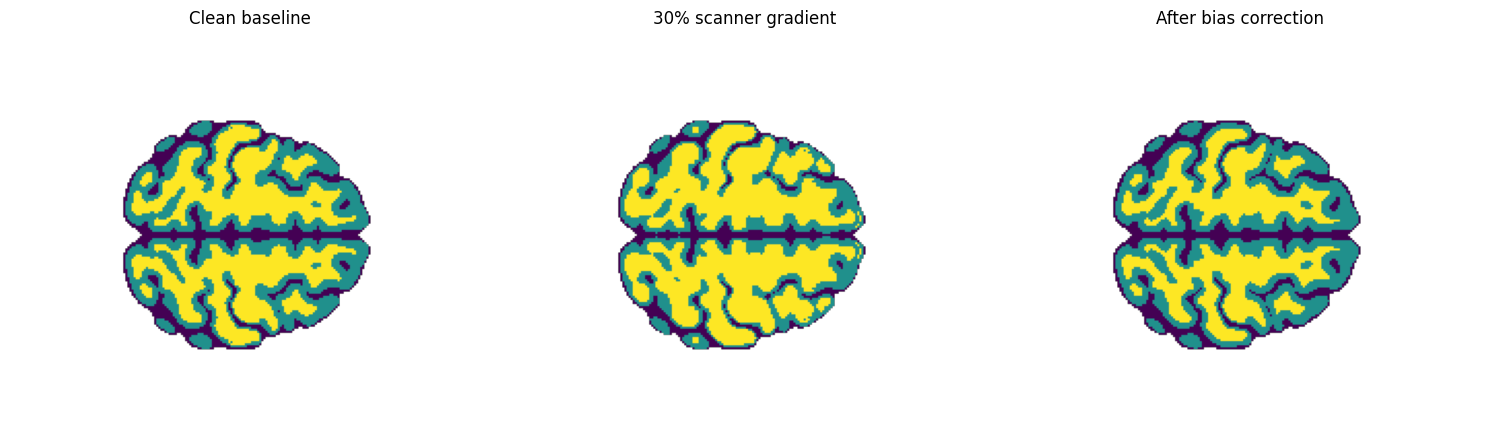

In [6]:
#----------------BRAIN SLICE: CLEAN VS CORRUPTED VS CORRECTED-------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5)) # 1 row, 3 plots, 15x5 inches
for ax, (p, title, d) in zip(axes, panels): #zip pairs each plot area w/ its panel, so loop runs 3 times
    ax.imshow(to_vol(p)[:, :, 130], cmap='viridis', vmin=0, vmax=2) #[:,:,130] grabs 1 horizontal slice
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.savefig("comparison_top_slice.png", dpi=150)
plt.show()

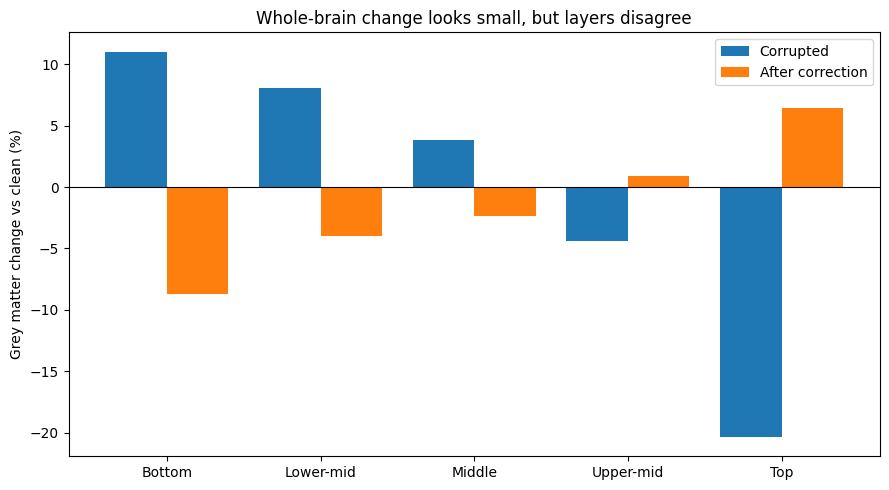

In [7]:
#----------------------SEESAW BAR CHART-------------------------
change_bad, change_fixed = [], [] #makes 2 empty lists to hold the % changes
for k in range(5):
    m = layer == k # selects that layer's voxels
    c = (pred[m] == 1).sum() # is the clean grey count in that layer
    change_bad.append(100 * ((pred_bad[m] == 1).sum() - c) / c)
    change_fixed.append(100 * ((pred_fixed[m] == 1).sum() - c) / c)

x = np.arange(5) # makes positions 0,1,2,3,4,5 for layers
plt.figure(figsize=(9, 5))
plt.bar(x - 0.2, change_bad, 0.4, label="Corrupted") # drwas corrupted bars shifted slightly left
plt.bar(x + 0.2, change_fixed, 0.4, label="After correction") # draws fixed abrs, shifted slightly right, so the two sit side by side
plt.axhline(0, color='black', lw=0.8)
plt.xticks(x, names)
plt.ylabel("Grey matter change vs clean (%)")
plt.title("Whole-brain change looks small, but layers disagree")
plt.legend()
plt.tight_layout()
plt.savefig("seesaw.png", dpi=150)
plt.show()